# Student Academic Performance Prediction Using Machine Learning

## Project Overview
This project applies machine-learning techniques to analyse and predict student academic performance using selected academic and behavioural factors.

The project compares Linear Regression and Random Forest Regression models and evaluates their performance using Mean Absolute Error (MAE), Mean Squared Error (MSE), and R-squared (R²).

## Tools Used
- Python
- Pandas
- NumPy
- Matplotlib
- Scikit-learn
- Google Colab

## Project Objectives

The objectives of this project are to:

1. Explore and understand student-performance data.
2. Identify factors associated with final academic performance.
3. Prepare the dataset for machine-learning analysis.
4. Develop a Linear Regression model for predicting final grades.
5. Develop a Random Forest Regression model for predicting final grades.
6. Compare the performance of the two models using MAE, MSE, and R².
7. Identify the better-performing model for student-performance prediction.

## Dataset

The project uses a student-performance dataset containing academic and behavioural variables that may influence final academic results.

Some of the variables used in the analysis include:

- Study hours
- Attendance
- Assignment scores
- Previous academic scores
- Participation
- Sleep hours
- Final grade

The dataset was analysed to identify relationships between these variables and student academic performance.

## Data Preparation

The dataset was inspected for:

- Missing values
- Data types
- Numerical variables
- Correlations between variables
- Suitable features for model development

Selected features were then used to train and test the machine-learning models.

## Exploratory Data Analysis

Exploratory Data Analysis (EDA) was carried out to understand the structure of the dataset and identify patterns in student academic performance.

The analysis included:

- Reviewing summary statistics
- Checking the distribution of final grades
- Examining relationships between numerical variables
- Conducting correlation analysis
- Identifying variables with stronger relationships to final academic performance

The correlation analysis showed that variables such as participation, previous academic score, study hours, assignment score, and attendance had positive relationships with the final grade.

## Correlation Findings

The strongest positive correlations with final academic performance were observed approximately as follows:

- Participation: 0.326
- Previous score: 0.266
- Study hours: 0.247
- Assignment score: 0.241
- Attendance: 0.196
- Sleep hours: 0.104

These findings helped guide the selection of variables used in the machine-learning models.

## Model Development

Two machine-learning regression models were developed and compared:

1. Linear Regression
2. Random Forest Regression

The dataset was divided into training and testing sets. The training data was used to train the models, while the testing data was used to evaluate how well the models predicted unseen student results.

The models were evaluated using:

- Mean Absolute Error (MAE)
- Mean Squared Error (MSE)
- R-squared (R²)

## Model Results

### Linear Regression

The Linear Regression model produced:

- Mean Absolute Error (MAE): 14.38
- R-squared (R²): -35.37

The negative R² value showed that the Linear Regression model performed poorly on the selected dataset.

### Random Forest Regression

The Random Forest model produced:

- Mean Absolute Error (MAE): 2.74
- R-squared (R²): 0.156

The Random Forest model performed substantially better than Linear Regression because it produced a much lower prediction error and a positive R² value.

Therefore, Random Forest was selected as the better-performing model in this project.

## Conclusion

This project demonstrated the use of machine-learning techniques to predict student academic performance.

Two models were developed and compared: Linear Regression and Random Forest Regression. Random Forest performed better, producing a lower Mean Absolute Error and a positive R-squared value.

The project provided practical experience in data preparation, exploratory data analysis, correlation analysis, feature selection, model training, prediction, and evaluation.

Although the Random Forest model performed better, the results also showed that the available variables did not explain all the variation in student performance. This means the model could be improved further with additional data and better features.

## Future Improvements

Future improvements to this project could include:

- Using a larger dataset
- Adding more relevant student-related variables
- Performing feature engineering
- Tuning the Random Forest model
- Testing additional models such as Gradient Boosting or XGBoost
- Developing a simple prediction dashboard using Streamlit
- Deploying the model as a small web application

## Project Information

**Project Title:** Student Academic Performance Prediction Using Machine Learning

**Author:** Katenderi Ketra Namuganza

**Field of Study:** Data Science and Artificial Intelligence

**Institution:** Cavendish University Uganda

**Project Type:** Data Science / Machine Learning Portfolio Project

**Tools Used:** Python, Pandas, NumPy, Matplotlib, Scikit-learn, Google Colab

In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries loaded successfully")

Libraries loaded successfully


In [51]:
data = {
    "study_hours": [2, 4, 1, 5, 3, 6, 2, 7, 4, 5],
    "attendance": [70, 85, 60, 90, 75, 95, 65, 98, 82, 88],
    "assignment_score": [65, 78, 55, 88, 72, 92, 60, 95, 80, 85],
    "previous_score": [60, 75, 50, 85, 70, 90, 58, 94, 77, 82],
    "sleep_hours": [6, 7, 5, 7, 6, 8, 5, 8, 7, 7],
    "participation": [5, 7, 4, 9, 6, 10, 5, 10, 8, 8],
    "final_score": [62, 76, 52, 88, 70, 93, 59, 96, 79, 84]
}

df = pd.DataFrame(data)

df

,study_hours,attendance,assignment_score,previous_score,sleep_hours,participation,final_score
0,2,70,65,60,6,5,62
1,4,85,78,75,7,7,76
2,1,60,55,50,5,4,52
3,5,90,88,85,7,9,88
4,3,75,72,70,6,6,70
5,6,95,92,90,8,10,93
6,2,65,60,58,5,5,59
7,7,98,95,94,8,10,96
8,4,82,80,77,7,8,79
9,5,88,85,82,7,8,84


In [52]:
df.describe()

,study_hours,attendance,assignment_score,previous_score,sleep_hours,participation,final_score
count,10.000000,10.000000,10.000000,10.00000,10.000000,10.000000,10.000000
mean,3.900000,80.800000,77.000000,74.10000,6.600000,7.200000,75.900000
std,1.911951,12.847827,13.686977,14.51015,1.074968,2.149935,14.917924
min,1.000000,60.000000,55.000000,50.00000,5.000000,4.000000,52.000000
25%,2.250000,71.250000,66.750000,62.50000,6.000000,5.250000,64.000000
50%,4.000000,83.500000,79.000000,76.00000,7.000000,7.500000,77.500000
75%,5.000000,89.500000,87.250000,84.25000,7.000000,8.750000,87.000000
max,7.000000,98.000000,95.000000,94.00000,8.000000,10.000000,96.000000


In [53]:
df.corr(numeric_only=True)

,study_hours,attendance,assignment_score,previous_score,sleep_hours,participation,final_score
study_hours,1.000000,0.985165,0.985057,0.989650,0.951476,0.978507,0.989088
attendance,0.985165,1.000000,0.994546,0.991885,0.975068,0.975068,0.991788
assignment_score,0.985057,0.994546,1.000000,0.997538,0.966639,0.985519,0.998568
previous_score,0.989650,0.991885,0.997538,1.000000,0.957391,0.985885,0.998434
sleep_hours,0.951476,0.975068,0.966639,0.957391,1.000000,0.951923,0.960322
participation,0.978507,0.975068,0.985519,0.985885,0.951923,1.000000,0.991501
final_score,0.989088,0.991788,0.998568,0.998434,0.960322,0.991501,1.000000


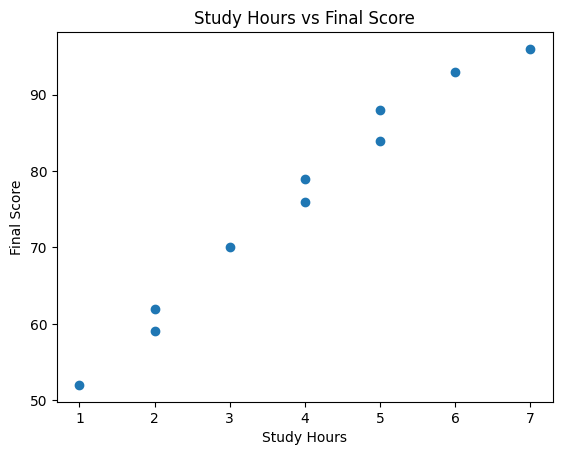

In [54]:
plt.scatter(df["study_hours"], df["final_score"])
plt.title("Study Hours vs Final Score")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.show()

In [55]:
x = df[["study_hours", "attendance", "assignment_score", "previous_score", "sleep_hours", "participation"]]
y = df["final_score"]
print(x)
print(y)

   study_hours  attendance  assignment_score  previous_score  sleep_hours  \
0            2          70                65              60            6   
1            4          85                78              75            7   
2            1          60                55              50            5   
3            5          90                88              85            7   
4            3          75                72              70            6   
5            6          95                92              90            8   
6            2          65                60              58            5   
7            7          98                95              94            8   
8            4          82                80              77            7   
9            5          88                85              82            7   

   participation  
0              5  
1              7  
2              4  
3              9  
4              6  
5             10  
6              5  


In [56]:
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)
print("Training data:", x_train.shape)
print("Testing data:", x_test.shape)

Training data: (8, 6)
Testing data: (2, 6)


In [57]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(x_train, y_train)
print("Model trained successfully")

Model trained successfully


In [58]:
predictions = model.predict(x_test)
print("Actual scores:")
print(y_test.values)
print("Predicted scores:")
print(predictions)

Actual scores:
[79 76]
Predicted scores:
[78.95625    77.71020833]


In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r2 = r2_score(y_test, predictions)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("R-squared:", r2)

Mean Absolute Error: 0.8769791666666578
Mean Squared Error: 1.4633633029513535
R-squared: 0.3496163097993984


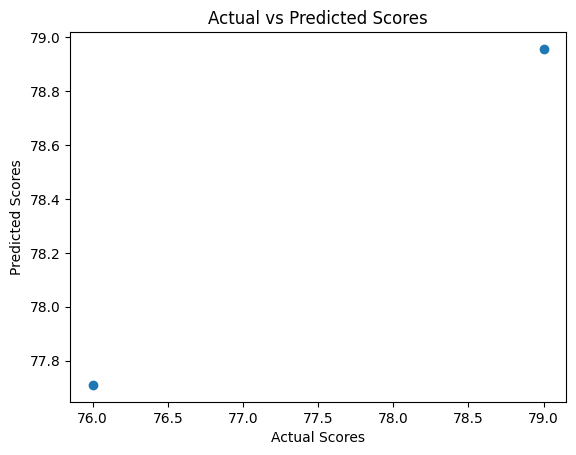

In [60]:
plt.scatter(y_test, predictions)
plt.xlabel("Actual Scores")
plt.ylabel("Predicted Scores")
plt.title("Actual vs Predicted Scores")
plt.show()
#

In [61]:
results = pd.DataFrame({"Actual Scores": y_test, "Predicted Scores": predictions})
print(results)
#

   Actual Scores  Predicted Scores
8             79         78.956250
1             76         77.710208


In [62]:
!pip install ucimlrepo

In [63]:
from ucimlrepo import fetch_ucirepo
student_performance = fetch_ucirepo(id=320)
X = student_performance.data.features
y = student_performance.data.targets
print("Features shape:", X.shape)
print("Target shape", y.shape)

Features shape: (649, 30)
Target shape (649, 3)


In [64]:
x.head()

,study_hours,attendance,assignment_score,previous_score,sleep_hours,participation
0,2,70,65,60,6,5
1,4,85,78,75,7,7
2,1,60,55,50,5,4
3,5,90,88,85,7,9
4,3,75,72,70,6,6


In [65]:
y.head()

,G1,G2,G3
0,0,11,11
1,9,11,11
2,12,13,12
3,14,14,14
4,11,13,13


In [66]:
x.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10 entries, 0 to 9
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   study_hours       10 non-null     int64
 1   attendance        10 non-null     int64
 2   assignment_score  10 non-null     int64
 3   previous_score    10 non-null     int64
 4   sleep_hours       10 non-null     int64
 5   participation     10 non-null     int64
dtypes: int64(6)
memory usage: 612.0 bytes


In [67]:
df_real = x.copy()
df_real["final_grade"] = y.iloc[:, 0]
df_real.head()

,study_hours,attendance,assignment_score,previous_score,sleep_hours,participation,final_grade
0,2,70,65,60,6,5,0
1,4,85,78,75,7,7,9
2,1,60,55,50,5,4,12
3,5,90,88,85,7,9,14
4,3,75,72,70,6,6,11


In [68]:
print("Rows:", df_real.shape[0])
print("Columns:", df_real.shape[1])

Rows: 10
Columns: 7


In [69]:
df_real.isnull().sum()

,0
study_hours,0
attendance,0
assignment_score,0
previous_score,0
sleep_hours,0
participation,0
final_grade,0


In [70]:
df_real["final_grade"].describe()

,final_grade
count,10.000000
mean,10.800000
std,4.184628
min,0.000000
25%,10.250000
50%,12.000000
75%,12.750000
max,15.000000


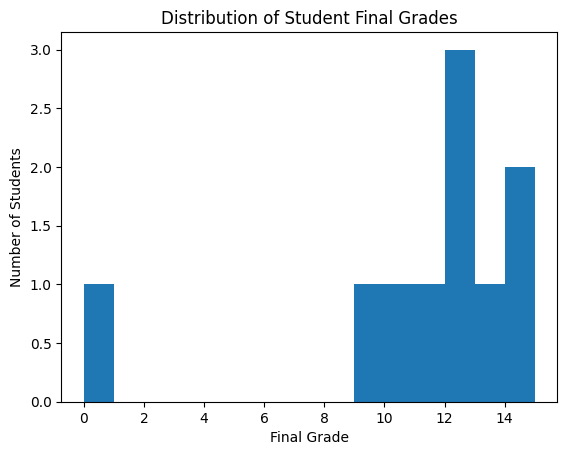

In [71]:
plt.hist(df_real["final_grade"], bins=15)
plt.xlabel("Final Grade")
plt.ylabel("Number of Students")
plt.title("Distribution of Student Final Grades")
plt.show()


In [72]:
print(df_real.columns.tolist())

['study_hours', 'attendance', 'assignment_score', 'previous_score', 'sleep_hours', 'participation', 'final_grade']


In [73]:
numeric_df = df_real.select_dtypes(include=["int64", "float64"])
numeric_df.corr()

,study_hours,attendance,assignment_score,previous_score,sleep_hours,participation,final_grade
study_hours,1.000000,0.985165,0.985057,0.989650,0.951476,0.978507,0.247197
attendance,0.985165,1.000000,0.994546,0.991885,0.975068,0.975068,0.195507
assignment_score,0.985057,0.994546,1.000000,0.997538,0.966639,0.985519,0.240555
previous_score,0.989650,0.991885,0.997538,1.000000,0.957391,0.985885,0.265702
sleep_hours,0.951476,0.975068,0.966639,0.957391,1.000000,0.951923,0.103742
participation,0.978507,0.975068,0.985519,0.985885,0.951923,1.000000,0.326046
final_grade,0.247197,0.195507,0.240555,0.265702,0.103742,0.326046,1.000000


In [74]:
correlations = numeric_df.corr()["final_grade"].sort_values(ascending=False)
print(correlations)


final_grade         1.000000
participation       0.326046
previous_score      0.265702
study_hours         0.247197
assignment_score    0.240555
attendance          0.195507
sleep_hours         0.103742
Name: final_grade, dtype: float64


In [75]:
x.head()

,study_hours,attendance,assignment_score,previous_score,sleep_hours,participation
0,2,70,65,60,6,5
1,4,85,78,75,7,7
2,1,60,55,50,5,4
3,5,90,88,85,7,9
4,3,75,72,70,6,6


In [76]:
df_real.shape

(10, 7)

In [77]:
df_real.isnull().sum()

,0
study_hours,0
attendance,0
assignment_score,0
previous_score,0
sleep_hours,0
participation,0
final_grade,0


In [78]:
print(df_real.columns.tolist())

['study_hours', 'attendance', 'assignment_score', 'previous_score', 'sleep_hours', 'participation', 'final_grade']


In [79]:
correlations = numeric_df.corr()["final_grade"].sort_values(ascending=False)
print(correlations)

final_grade         1.000000
participation       0.326046
previous_score      0.265702
study_hours         0.247197
assignment_score    0.240555
attendance          0.195507
sleep_hours         0.103742
Name: final_grade, dtype: float64


In [80]:
features = [
    "participation",
    "previous_score",
    "study_hours",
    "assignment_score",
    "attendance",
    "sleep_hours"
]

X_model = df_real[features]
y_model = df_real["final_grade"]

print(X_model.head())
print(y_model.head())

   participation  previous_score  study_hours  assignment_score  attendance  \
0              5              60            2                65          70   
1              7              75            4                78          85   
2              4              50            1                55          60   
3              9              85            5                88          90   
4              6              70            3                72          75   

   sleep_hours  
0            6  
1            7  
2            5  
3            7  
4            6  
0     0
1     9
2    12
3    14
4    11
Name: final_grade, dtype: int64


In [81]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_model,
    y_model,
    test_size=0.2,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 8
Testing rows: 2


In [82]:
from sklearn.linear_model import LinearRegression

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully")

Linear Regression model trained successfully


In [83]:
linear_predictions = linear_model.predict(X_test)

print(linear_predictions[:10])

[ 18.4  -16.36]


In [84]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_mse = mean_squared_error(y_test, linear_predictions)
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression Results")
print("MAE:", linear_mae)
print("MSE:", linear_mse)
print("R-squared:", linear_r2)

Linear Regression Results
MAE: 14.380000000000052
MSE: 327.34480000000127
R-squared: -35.371644444444584


In [85]:
print(df_real["final_grade"].describe())
print(df_real["final_grade"].head(20))

count    10.000000
mean     10.800000
std       4.184628
min       0.000000
25%      10.250000
50%      12.000000
75%      12.750000
max      15.000000
Name: final_grade, dtype: float64
0     0
1     9
2    12
3    14
4    11
5    12
6    13
7    10
8    15
9    12
Name: final_grade, dtype: int64


In [86]:
print(df_real.shape)

(10, 7)


In [87]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

In [88]:
rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_mse = mean_squared_error(y_test, rf_predictions)
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Results")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("R-squared:", rf_r2)

Random Forest Results
MAE: 2.74
MSE: 7.594625000000001
R-squared: 0.1561527777777777


In [89]:
print("MODEL COMPARISON")
print("------------------------")
print("Linear Regression")
print("MAE:", linear_mae)
print("R²:", linear_r2)

print()

print("Random Forest")
print("MAE:", rf_mae)
print("R²:", rf_r2)

MODEL COMPARISON
------------------------
Linear Regression
MAE: 14.380000000000052
R²: -35.371644444444584

Random Forest
MAE: 2.74
R²: 0.1561527777777777


In [90]:
import pandas as pd

importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

            Feature  Importance
4        attendance    0.219773
1    previous_score    0.184745
3  assignment_score    0.181491
0     participation    0.151425
5       sleep_hours    0.135376
2       study_hours    0.127189


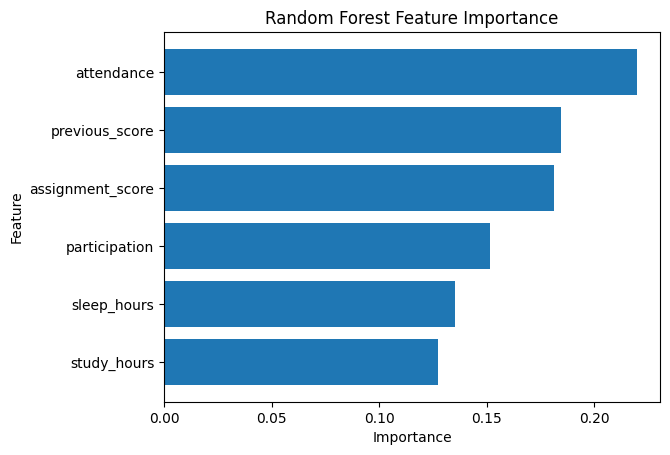

In [91]:
plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")
plt.gca().invert_yaxis()

plt.show()

In [92]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [None, 5, 10],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

grid_search = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best Cross-Validation R²:")
print(grid_search.best_score_)

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan
 nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}
Best Cross-Validation R²:
nan


In [93]:
best_rf = grid_search.best_estimator_

best_predictions = best_rf.predict(X_test)

best_mae = mean_absolute_error(
    y_test,
    best_predictions
)

best_mse = mean_squared_error(
    y_test,
    best_predictions
)

best_r2 = r2_score(
    y_test,
    best_predictions
)

print("Tuned Random Forest Results")
print("MAE:", best_mae)
print("MSE:", best_mse)
print("R²:", best_r2)

Tuned Random Forest Results
MAE: 2.6399999999999997
MSE: 7.053699999999997
R²: 0.21625555555555587
